# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

Africa experienced the fastest population growth relative to its 1970 population. By 2022, its population index reached 390.4, meaning its population became approximately 3.9 times its 1970 size. Oceania followed at 231.2, while Europe had the slowest relative growth at 113.3.

I chose a line chart because it clearly shows how the population of each continent changed over time. Indexing the population to 1970 = 100 makes it possible to compare relative growth fairly, even though continents had different starting population sizes. 

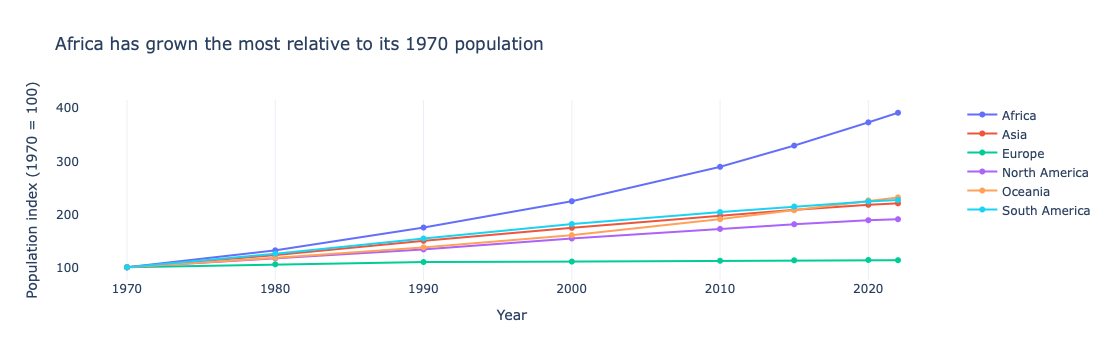

Population growth index in 2022:
    Continent  Index (1970=100)
       Africa             390.4
      Oceania             231.2
South America             226.4
         Asia             220.1
North America             190.3
       Europe             113.3


In [9]:

# Q1: Relative population growth (1970 = 100)

continent_year = df_long.groupby(
    ['Continent', 'Year'], as_index=False
)['Population'].sum()

base = continent_year[
    continent_year['Year'] == 1970
][['Continent', 'Population']].rename(
    columns={'Population': 'Base1970'}
)

continent_year = continent_year.merge(base, on='Continent')

continent_year['Index (1970=100)'] = (
    continent_year['Population'] /
    continent_year['Base1970'] * 100
)

growth_2022 = continent_year[
    continent_year['Year'] == 2022
].sort_values('Index (1970=100)', ascending=False)

fastest = growth_2022.iloc[0]['Continent']

fig = px.line(
    continent_year,
    x='Year',
    y='Index (1970=100)',
    color='Continent',
    markers=True,
    title=f'{fastest} has grown the most relative to its 1970 population',
    labels={
        'Index (1970=100)': 'Population index (1970 = 100)',
        'Year': 'Year'
    }
)

fig.update_layout(
    template='plotly_white',
    legend_title_text='',
    hovermode='x unified'
)

fig.update_yaxes(showgrid=False)

fig.show()

print("Population growth index in 2022:")
print(
    growth_2022[
        ['Continent', 'Index (1970=100)']
    ].round(1).to_string(index=False)
)

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

Four of the 15 countries are in Africa: Nigeria, Ethiopia, the Democratic Republic of the Congo, and Egypt.

I chose a horizontal bar chart showing the 15 countries ranked from the largest to the smallest population increase. A horizontal bar chart makes it easy to compare the values and read country names clearly. I used a contrasting colour to highlight the African countries, while keeping the other countries in a consistent colour. I also included a clear title, axis labels, and population-increase values so the main findings are easy to understand.

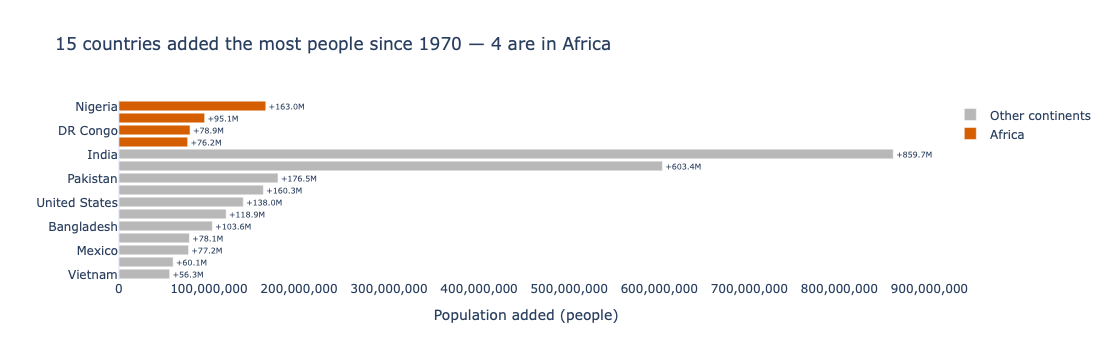

African countries among the top 15: 4
      Country     Continent     Added
        India          Asia 859671872
        China          Asia 603352887
     Pakistan          Asia 176533990
      Nigeria        Africa 162971948
    Indonesia          Asia 160272945
United States North America 137961517
       Brazil South America 118943623
   Bangladesh          Asia 103644512
     Ethiopia        Africa  95071678
     DR Congo        Africa  78858479
  Philippines          Asia  78123423
       Mexico North America  77214819
        Egypt        Africa  76208117
         Iran          Asia  60100865
      Vietnam          Asia  56258007


In [10]:

# Q2: Top 15 countries by population added

q2 = df.copy()

q2['Added'] = (
    q2['2022 Population'] -
    q2['1970 Population']
)

top15 = q2.nlargest(15, 'Added').sort_values('Added')

africa_count = int(
    (top15['Continent'] == 'Africa').sum()
)

top15['Region'] = np.where(
    top15['Continent'] == 'Africa',
    'Africa',
    'Other continents'
)

fig = px.bar(
    top15,
    x='Added',
    y='Country',
    orientation='h',
    color='Region',
    color_discrete_map={
        'Africa': '#D55E00',
        'Other continents': '#B8B8B8'
    },
    text=top15['Added'].map(
        lambda x: f'+{x/1e6:.1f}M'
    ),
    title=f'15 countries added the most people since 1970 — {africa_count} are in Africa',
    labels={
        'Added': 'Population added (people)',
        'Country': ''
    }
)

fig.update_traces(
    textposition='outside',
    cliponaxis=False
)

fig.update_layout(
    template='plotly_white',
    legend_title_text=''
)

fig.update_xaxes(showgrid=False, tickformat=',.0f')
fig.update_yaxes(showgrid=False)

fig.show()

print("African countries among the top 15:", africa_count)

print(
    top15[
        ['Country', 'Continent', 'Added']
    ].sort_values(
        'Added', ascending=False
    ).to_string(index=False)
)

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

There is a positive relationship between land area and population: bigger countries often have more people. However, this is not always true. India and China have very large populations, while Australia has a large area but fewer people. Singapore and Bangladesh have many people in a small area.

I chose a scatter plot to compare land area and population. I used different colours for each continent and logarithmic scales to make the differences easier to see. I highlighted countries that do not follow the general pattern.

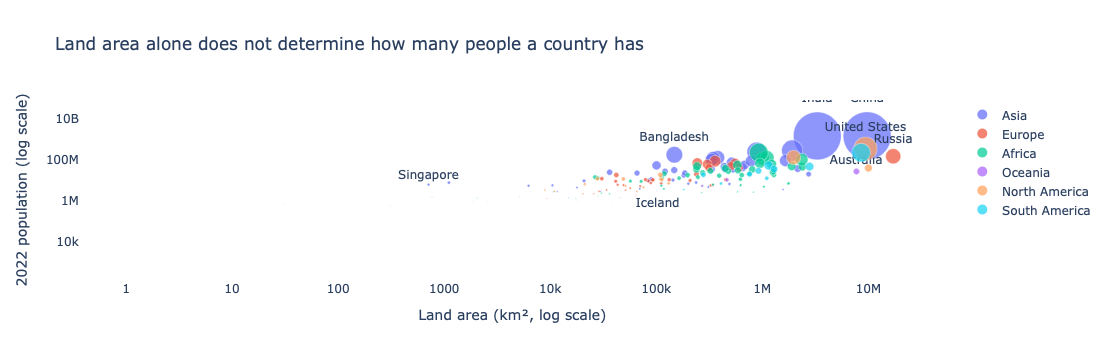

Countries with highest population density:
  Country Continent  Area  2022 Population    Density
    Macau      Asia    30           695168 23172.2667
   Monaco    Europe     2            36469 18234.5000
Singapore      Asia   710          5975689  8416.4634
Hong Kong      Asia  1104          7488865  6783.3922
Gibraltar    Europe     6            32649  5441.5000
  Bahrain      Asia   765          1472233  1924.4876
 Maldives      Asia   300           523787  1745.9567
    Malta    Europe   316           533286  1687.6139


In [4]:
# Q3
# Q3: Land area versus 2022 population

q3 = df[
    (df['Area'] > 0) &
    (df['2022 Population'] > 0)
].copy()

labels = [
    'India',
    'China',
    'United States',
    'Russia',
    'Bangladesh',
    'Singapore',
    'Iceland',
    'Australia'
]

q3['Label'] = np.where(
    q3['Country'].isin(labels),
    q3['Country'],
    ''
)

fig = px.scatter(
    q3,
    x='Area',
    y='2022 Population',
    color='Continent',
    size='World share (%)',
    size_max=34,
    hover_name='Country',
    text='Label',
    log_x=True,
    log_y=True,
    title='Land area alone does not determine how many people a country has',
    labels={
        'Area': 'Land area (km², log scale)',
        '2022 Population': '2022 population (log scale)',
        'World share (%)': 'World share (%)'
    }
)

fig.update_traces(
    textposition='top center',
    marker=dict(
        opacity=0.72,
        line=dict(width=0.5, color='white')
    )
)

fig.update_layout(
    template='plotly_white',
    legend_title_text=''
)

fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)

fig.show()

print("Countries with highest population density:")

print(
    q3.nlargest(8, 'Density')[
        ['Country', 'Continent', 'Area',
         '2022 Population', 'Density']
    ].to_string(index=False)
)

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

Population density varies a lot between continents. North America has the highest median density (221 people/km²), while South America has the lowest (18 people/km²). Asia has the biggest extremes, including very crowded places such as Macau and Singapore. This shows that population density varies greatly within each continent.

I chose a violin plot to show the spread and differences in population density across continents. Different colours make the continents easy to compare, and the plot shows both common values and extreme outliers.

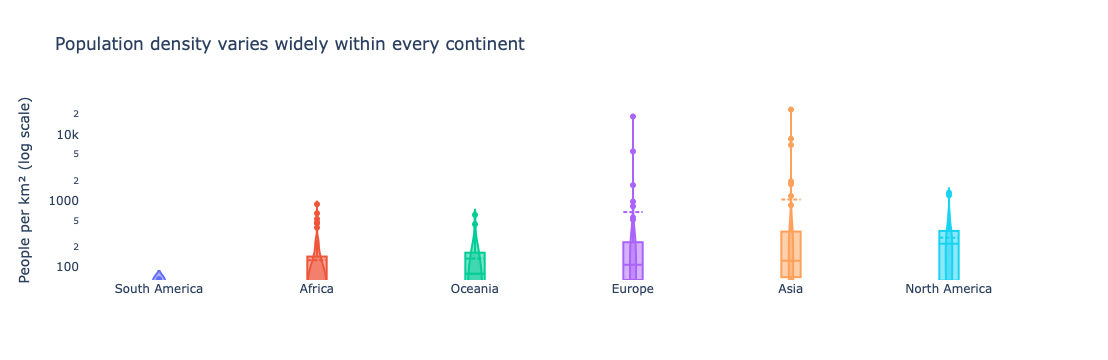

Density summary by continent:
               min  median      max
Continent                          
Africa         2.2    59.7    871.9
Asia           2.2   123.0  23172.3
Europe         3.6   106.9  18234.5
North America  0.0   221.4   1299.3
Oceania        3.4    78.2    603.2
South America  0.3    17.8     65.0


In [5]:
# Q4
# Q4: Population density distribution by continent

q4 = df[
    (df['Density'] > 0) &
    df['Density'].notna()
].copy()

continent_order = (
    q4.groupby('Continent')['Density']
    .median()
    .sort_values()
    .index.tolist()
)

fig = px.violin(
    q4,
    x='Continent',
    y='Density',
    color='Continent',
    category_orders={
        'Continent': continent_order
    },
    box=True,
    points='outliers',
    log_y=True,
    title='Population density varies widely within every continent',
    labels={
        'Density': 'People per km² (log scale)',
        'Continent': ''
    }
)

fig.update_traces(
    meanline_visible=True,
    showlegend=False
)

fig.update_layout(template='plotly_white')

fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)

fig.show()

print("Density summary by continent:")

print(
    q4.groupby('Continent')['Density']
    .agg(['min', 'median', 'max'])
    .round(1)
    .to_string()
)

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

Between 2000 and 2022, populations grew strongly in countries such as **Qatar (+317.2%)**, **United Arab Emirates (+188.2%)**, and **Niger (+125.5%)**. Some countries experienced population decline, including **Northern Mariana Islands (-38.3%)**, **American Samoa (-24.0%)**, and **Lithuania (-23.6%)**. Growth occurred in parts of Africa and the Middle East, while declines appeared in parts of Europe and some island territories.

I chose a world map (choropleth) to show where populations increased or decreased. Different colours show growth and decline clearly, making geographical patterns easy to identify.

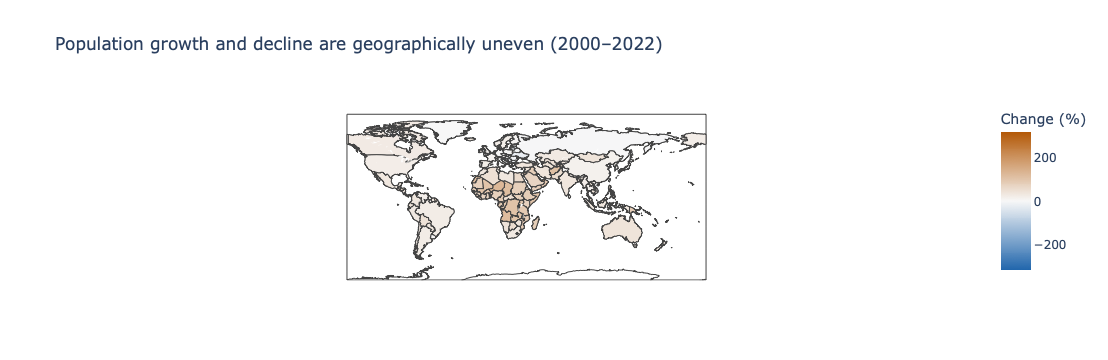

Countries with population decline:
                 Country     Continent  Change (%)
Northern Mariana Islands       Oceania       -38.3
          American Samoa       Oceania       -24.0
               Lithuania        Europe       -23.6
        Marshall Islands       Oceania       -23.3
                 Moldova        Europe       -23.0
                  Latvia        Europe       -22.6
  Bosnia and Herzegovina        Europe       -22.6
            Vatican City        Europe       -21.7
       Wallis and Futuna       Oceania       -21.4
                 Ukraine        Europe       -18.8
                Bulgaria        Europe       -16.2
              Martinique North America       -15.0
             Puerto Rico North America       -15.0
              Montserrat North America       -14.6
                 Armenia          Asia       -12.2

Countries with fastest growth:
                 Country     Continent  Change (%)
                   Qatar          Asia       317.2
    United Arab

In [6]:
# Q5
# Q5: Population percentage change from 2000 to 2022

q5 = df.copy()

q5['Change (%)'] = (
    (q5['2022 Population'] - q5['2000 Population']) /
    q5['2000 Population']
) * 100

q5['Direction'] = np.where(
    q5['Change (%)'] >= 0,
    'Growth',
    'Decline'
)

fig = px.choropleth(
    q5,
    locations='CCA3',
    locationmode='ISO-3',
    color='Change (%)',
    hover_name='Country',
    hover_data={
        'Continent': True,
        'Change (%)': ':.1f',
        'CCA3': False
    },
    color_continuous_scale=[
        '#2166AC',
        '#F7F7F7',
        '#B35806'
    ],
    color_continuous_midpoint=0,
    title='Population growth and decline are geographically uneven (2000–2022)',
    labels={
        'Change (%)': 'Population change (%)'
    }
)

fig.update_layout(
    template='plotly_white',
    coloraxis_colorbar_title='Change (%)'
)

fig.show()

print("Countries with population decline:")

print(
    q5.nsmallest(15, 'Change (%)')[
        ['Country', 'Continent', 'Change (%)']
    ].round(1).to_string(index=False)
)

print("\nCountries with fastest growth:")

print(
    q5.nlargest(15, 'Change (%)')[
        ['Country', 'Continent', 'Change (%)']
    ].round(1).to_string(index=False)
)

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

In 2022, the world population was about **7.97 billion**. Asia had the largest share, with **4.72 billion people (59.2%)**, followed by Africa with **1.43 billion (17.9%)** and Europe with **743 million (9.3%)**. North America, South America, and Oceania made up the remaining population.

I chose a treemap to show continents and the countries within them in one figure. The size of each rectangle represents population, making it easy to compare both continents and individual countries.

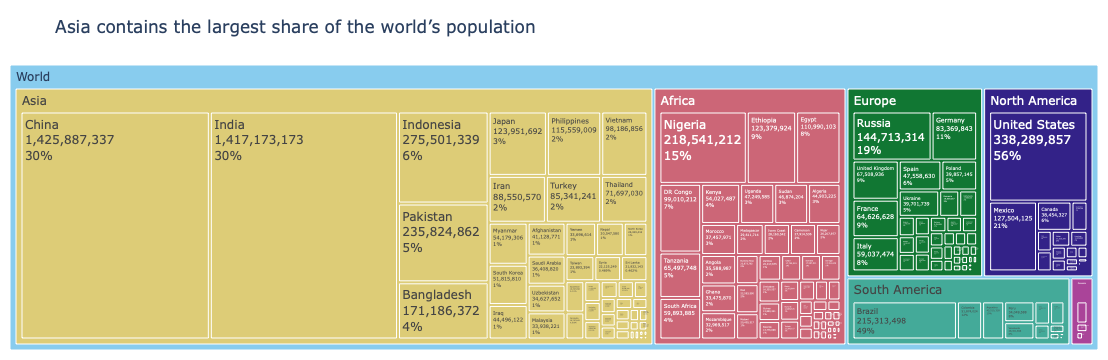

2022 population by continent:
Continent
Asia             4721383274
Africa           1426730932
Europe            743147538
North America     600296136
South America     436816608
Oceania            45038554


In [7]:
# Q6
# Q6: Population distribution by continent and country

q6 = df[
    df['2022 Population'] > 0
].copy()

fig = px.treemap(
    q6,
    path=[
        px.Constant('World'),
        'Continent',
        'Country'
    ],
    values='2022 Population',
    color='Continent',
    color_discrete_sequence=px.colors.qualitative.Safe,
    title='Asia contains the largest share of the world’s population',
    hover_data={
        '2022 Population': ':,',
        'World share (%)': ':.2f'
    }
)

fig.update_traces(
    root_color='#E6E6E6',
    textinfo='label+percent parent+value',
    hovertemplate=(
        '<b>%{label}</b><br>'
        'Population: %{value:,.0f}<br>'
        'Share of parent: %{percentParent:.1%}'
        '<extra></extra>'
    )
)

fig.update_layout(
    template='plotly_white',
    margin=dict(t=65, l=10, r=10, b=10)
)

fig.show()

print("2022 population by continent:")

print(
    q6.groupby('Continent')['2022 Population']
    .sum()
    .sort_values(ascending=False)
    .to_string()
)

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

From 1970 to 2022, Africa's share of the world population increased from **9.9% to 17.9%**. Europe's share decreased from **17.8% to 9.3%**. Asia remained the largest, changing from **58.1% to 59.2%**. The rest of the world accounted for **13.6%** in 2022.

I chose a 100% stacked bar chart to compare population shares over time. Different colours represent each group, making it easy to see how their shares changed from 1970 to 2022.

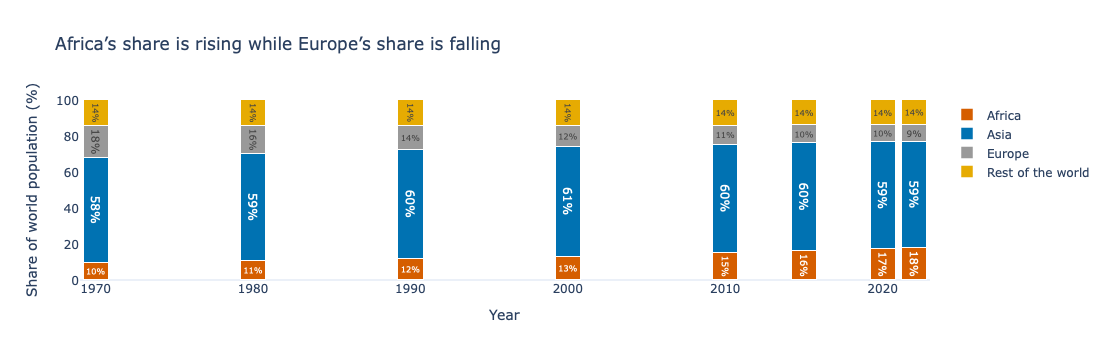

World population share by group (%):
Group  Africa  Asia  Europe  Rest of the world
Year                                          
1970      9.9  58.1    17.8               14.3
1980     10.8  59.3    15.6               14.2
1990     12.0  60.4    13.6               14.0
2000     13.3  60.8    11.8               14.1
2010     15.1  60.4    10.5               13.9
2015     16.2  60.0    10.0               13.8
2020     17.4  59.5     9.5               13.6
2022     17.9  59.2     9.3               13.6


In [8]:
# Q7
# Q7: World population share by continent over time

share = df_long.groupby(
    ['Year', 'Continent'],
    as_index=False
)['Population'].sum()

world = share.groupby(
    'Year',
    as_index=False
)['Population'].sum().rename(
    columns={'Population': 'World total'}
)

share = share.merge(world, on='Year')

share['Share (%)'] = (
    share['Population'] /
    share['World total'] * 100
)

share['Group'] = np.where(
    share['Continent'].isin(
        ['Africa', 'Asia', 'Europe']
    ),
    share['Continent'],
    'Rest of the world'
)

share_group = share.groupby(
    ['Year', 'Group'],
    as_index=False
)['Population'].sum()

share_group = share_group.merge(
    world,
    on='Year'
)

share_group['Share (%)'] = (
    share_group['Population'] /
    share_group['World total'] * 100
)

fig = px.bar(
    share_group,
    x='Year',
    y='Share (%)',
    color='Group',
    color_discrete_map={
        'Africa': '#D55E00',
        'Asia': '#0072B2',
        'Europe': '#999999',
        'Rest of the world': '#E6AB02'
    },
    barmode='stack',
    text=share_group['Share (%)'].map(
        lambda x: f'{x:.0f}%'
    ),
    title='Africa’s share is rising while Europe’s share is falling',
    labels={
        'Share (%)': 'Share of world population (%)',
        'Year': 'Year',
        'Group': ''
    }
)

fig.update_traces(
    textposition='inside',
    insidetextanchor='middle'
)

fig.update_layout(
    template='plotly_white',
    yaxis_range=[0, 100],
    legend_title_text=''
)

fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)

fig.show()

print("World population share by group (%):")

print(
    share_group.pivot(
        index='Year',
        columns='Group',
        values='Share (%)'
    ).round(1).to_string()
)